<a href="https://colab.research.google.com/github/Windshine11/GHG_PE_Data_Analysis/blob/main/Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd #basic data
import matplotlib.pyplot as plt #basic data
import numpy as np #basic data
from scipy.stats import pearsonr #corr
from scipy.stats import spearmanr #corr
from sklearn.linear_model import LinearRegression #linreg
from sklearn.metrics import mean_squared_error #linreg
import statsmodels.api as sm # For linear regression p-values

In [ ]:
class Analysis:
  def __init__(self, name):
    self.filename = name
    self.data = None

  def read_data(self):
    self.data = pd.read_csv(f"drive/MyDrive/Research/{self.filename}.csv")

  def transform_data(self):
    self.data = self.data.dropna().reset_index(drop=True)
    ghg_mean = self.data['GHG'].mean()
    ghg_std = self.data['GHG'].std()
    pe_mean = self.data['PE'].mean()
    pe_std = self.data['PE'].std()
    self.data['GHG'] = self.data['GHG'].clip(lower = 0, upper = 10000000)
    self.data['PE'] = self.data['PE'].clip(lower = 0, upper = 100)
    self.data['GHG'] = np.log1p(self.data['GHG'])

  def descriptive_statistics(self):
    table = self.data.describe().round(2)
    display(table)

  def correlation_values(self):
    a = self.data["GHG"]
    b = self.data["PE"]
    r_coef, r_p = pearsonr(a, b)
    rho_coef, rho_p = spearmanr(a, b)
    print(f"Pearson r: {r_coef:.3f}, p: {r_p:.3f}")
    print(f"Spearman rho {rho_coef:.3f}, p: {rho_p:.3f}")

  def linear_regression(self):
    X = self.data[["GHG"]]
    y = self.data[["PE"]]

    X = sm.add_constant(X)
    model = sm.OLS(y, X).fit()
    print(model.summary())
    sklearn_model = LinearRegression()
    sklearn_model.fit(self.data[["GHG"]], y)
    y_pred = sklearn_model.predict(self.data[["GHG"]])
    MSE = mean_squared_error(y, y_pred)
    print(f"Mean Squared Error: {MSE:.3f}")
    plt.scatter(self.data["GHG"], y, color = "blue", label = "Companies")
    plt.plot(self.data[["GHG"]], y_pred, color = "red", linewidth = 2, label = "Regression Line")
    plt.xlabel("Log Transformed GHG Emissions (mtCO2e)")
    plt.ylabel("P/E Ratio")
    plt.title(f"Linear Regression for {self.filename}")
    plt.show()

  def linear_regression_with_companies(self):
    X = self.data[["GHG"]]
    y = self.data[["PE"]]
    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)
    MSE = mean_squared_error(y, y_pred)
    apple_data = self.data[self.data['Ticker'] == 'AAPL']
    nvidia_data = self.data[self.data['Ticker'] == 'NVDA']
    microsoft_data = self.data[self.data['Ticker'] == 'MSFT']
    if not apple_data.empty:
        plt.scatter(apple_data["GHG"], apple_data["PE"], color="orange", label="Apple")
    if not nvidia_data.empty:
        plt.scatter(nvidia_data["GHG"], nvidia_data["PE"], color="green", label="NVIDIA")
    if not microsoft_data.empty:
          plt.scatter(microsoft_data["GHG"], microsoft_data["PE"], color="purple", label="Microsoft")
    other_companies_data = self.data[~self.data['Ticker'].isin(['AAPL', 'NVDA', 'MSFT'])]
    plt.scatter(other_companies_data["GHG"], other_companies_data["PE"], color="blue", label="Other Companies")
    plt.plot(X, y_pred, color = "red", linewidth = 2, label = "Regression Line")
    plt.xlabel("Log Transformed GHG Emissions (mtCO2e)")
    plt.ylabel("P/E Ratio")
    plt.title(f"Linear Regression for {self.filename}")
    plt.legend()
    plt.show()

,GHG,PE
count,56.00,56.00
mean,13.80,35.87
std,1.67,23.56
min,9.21,8.20
25%,12.51,20.29
50%,13.99,27.48
75%,15.21,44.62
max,16.12,100.00


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                 -0.010
Method:                 Least Squares   F-statistic:                    0.4595
Date:                Sat, 11 Jul 2026   Prob (F-statistic):              0.501
Time:                        22:14:14   Log-Likelihood:                -255.66
No. Observations:                  56   AIC:                             515.3
Df Residuals:                      54   BIC:                             519.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         53.7654     26.589      2.022      0.0

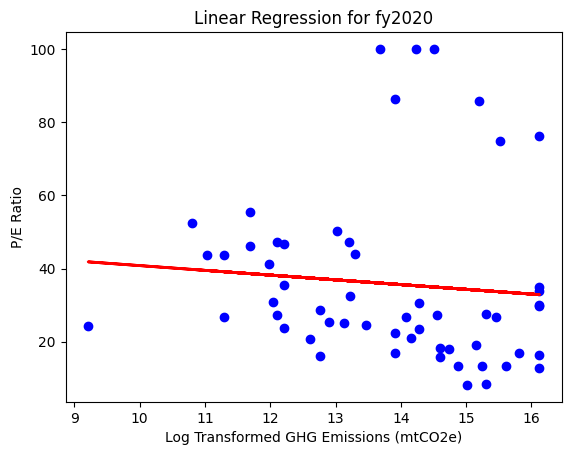

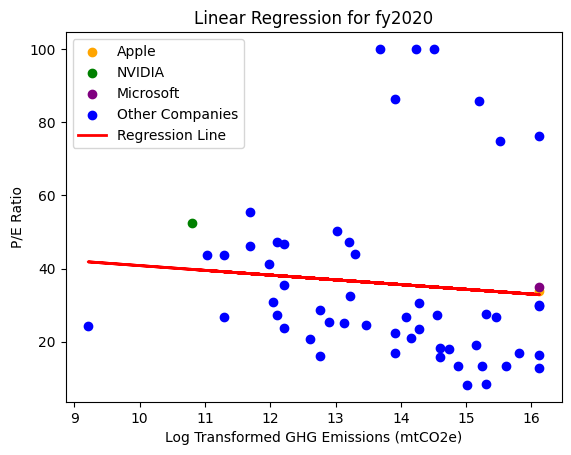

In [ ]:
#Analysis for 2020
fy2020 = Analysis("fy2020")
fy2020.read_data()
fy2020.transform_data()
fy2020.descriptive_statistics()
fy2020.linear_regression()
fy2020.linear_regression_with_companies()

,GHG,PE
count,72.00,72.00
mean,13.52,37.67
std,1.74,23.47
min,9.39,0.00
25%,12.13,21.00
50%,13.49,31.25
75%,14.97,48.95
max,16.12,100.00


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.085
Method:                 Least Squares   F-statistic:                     7.598
Date:                Sat, 11 Jul 2026   Prob (F-statistic):            0.00744
Time:                        22:14:14   Log-Likelihood:                -325.17
No. Observations:                  72   AIC:                             654.3
Df Residuals:                      70   BIC:                             658.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         94.6827     20.853      4.541      0.0

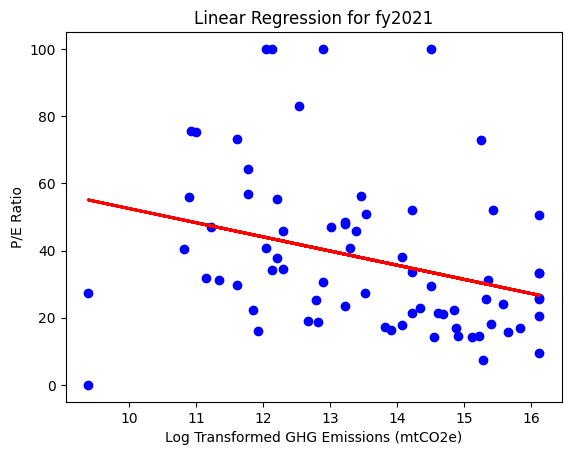

In [ ]:
#Analysis for 2021
fy2021 = Analysis("fy2021")
fy2021.read_data()
fy2021.transform_data()
fy2021.descriptive_statistics()
fy2021.linear_regression()

,GHG,PE
count,84.00,84.00
mean,13.26,30.08
std,1.92,22.31
min,9.21,0.00
25%,11.97,14.56
50%,13.33,25.82
75%,14.72,36.45
max,16.12,100.00


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.050
Method:                 Least Squares   F-statistic:                     5.328
Date:                Sat, 11 Jul 2026   Prob (F-statistic):             0.0235
Time:                        22:14:15   Log-Likelihood:                -376.86
No. Observations:                  84   AIC:                             757.7
Df Residuals:                      82   BIC:                             762.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         68.2227     16.693      4.087      0.0

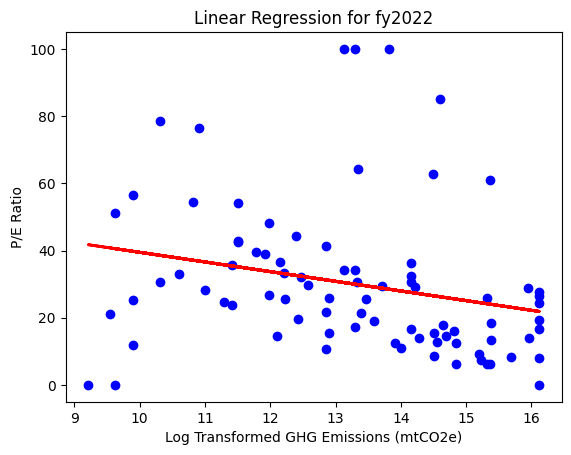

In [ ]:
#Analysis for 2022
fy2022 = Analysis("fy2022")
fy2022.read_data()
fy2022.transform_data()
fy2022.descriptive_statistics()
fy2022.linear_regression()

,GHG,PE
count,86.00,86.00
mean,13.32,38.10
std,1.88,25.85
min,9.62,0.00
25%,12.10,20.02
50%,13.38,28.82
75%,14.76,42.32
max,16.12,100.00


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.079
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     7.249
Date:                Sat, 11 Jul 2026   Prob (F-statistic):            0.00856
Time:                        22:14:15   Log-Likelihood:                -397.68
No. Observations:                  86   AIC:                             799.4
Df Residuals:                      84   BIC:                             804.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         89.6863     19.348      4.635      0.0

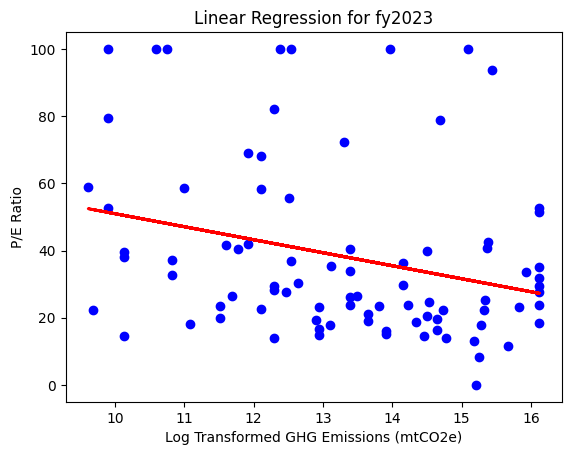

In [ ]:
#Analysis for 2023
fy2023 = Analysis("fy2023")
fy2023.read_data()
fy2023.transform_data()
fy2023.descriptive_statistics()
fy2023.linear_regression()

,GHG,PE
count,86.00,86.00
mean,13.46,38.58
std,1.82,25.03
min,9.80,0.00
25%,12.21,20.82
50%,13.49,31.90
75%,14.80,46.99
max,16.12,100.00


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.038
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     3.281
Date:                Sat, 11 Jul 2026   Prob (F-statistic):             0.0737
Time:                        22:14:15   Log-Likelihood:                -396.80
No. Observations:                  86   AIC:                             797.6
Df Residuals:                      84   BIC:                             802.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         74.4112     19.959      3.728      0.0

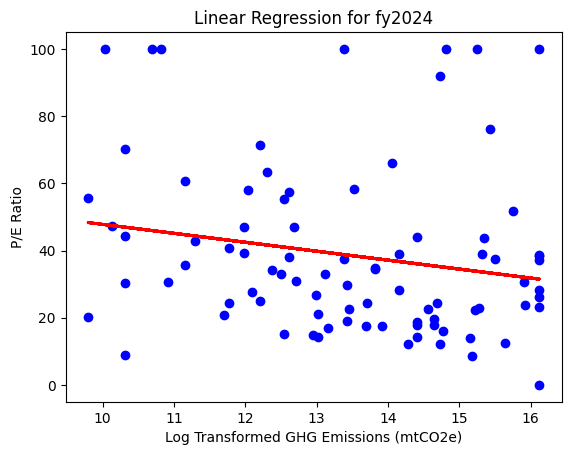

In [ ]:
#Analysis for 2024
fy2024 = Analysis("fy2024")
fy2024.read_data()
fy2024.transform_data()
fy2024.descriptive_statistics()
fy2024.linear_regression()

In [ ]:
years = ['fy2020', 'fy2021', 'fy2022', 'fy2023', 'fy2024']
results = []

for year in years:
    analysis_obj = Analysis(year)
    analysis_obj.read_data()
    analysis_obj.transform_data()

    a = analysis_obj.data["GHG"]
    b = analysis_obj.data["PE"]

    r_coef, r_p = pearsonr(a, b)
    rho_coef, rho_p = spearmanr(a, b)

    results.append({
        'Year': year,
        'Pearson_r': r_coef,
        'Pearson_p': r_p,
        'Spearman_rho': rho_coef,
        'Spearman_p': rho_p
    })

correlation_df = pd.DataFrame(results).round(3)
display(correlation_df)

,Year,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,fy2020,-0.092,0.501,-0.298,0.026
1,fy2021,-0.313,0.007,-0.399,0.001
2,fy2022,-0.247,0.024,-0.385,0.000
3,fy2023,-0.282,0.009,-0.277,0.010
4,fy2024,-0.194,0.074,-0.225,0.037


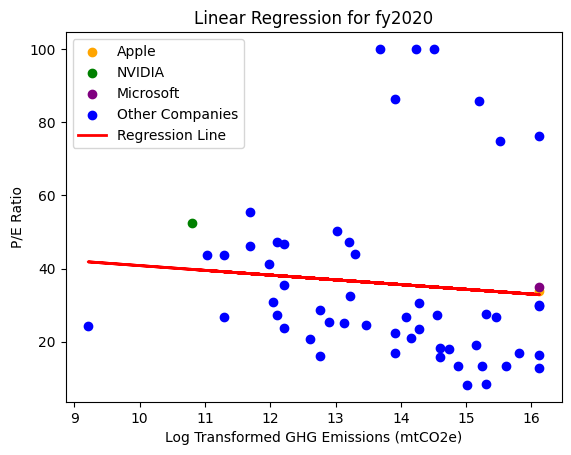

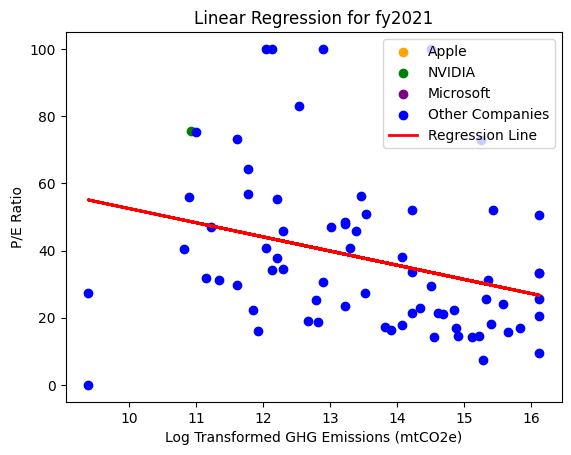

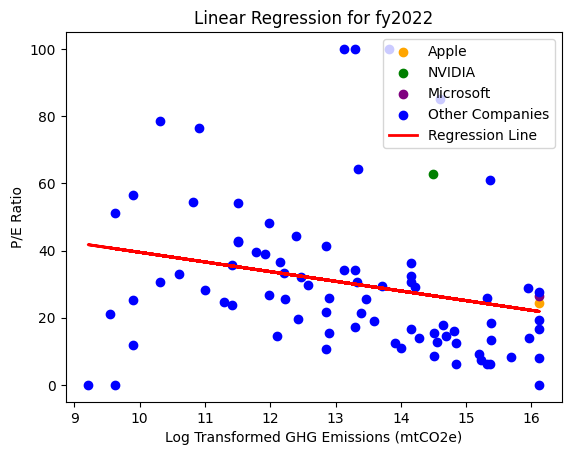

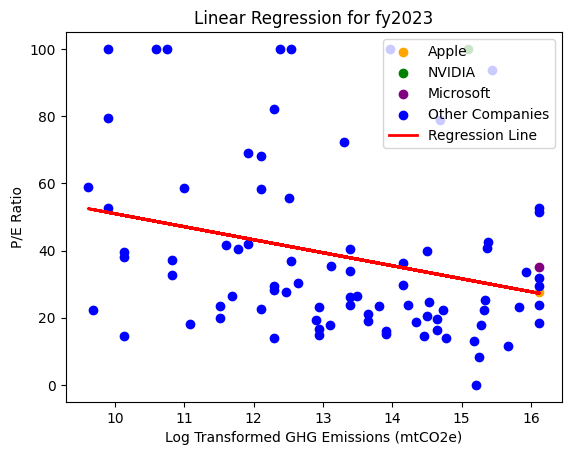

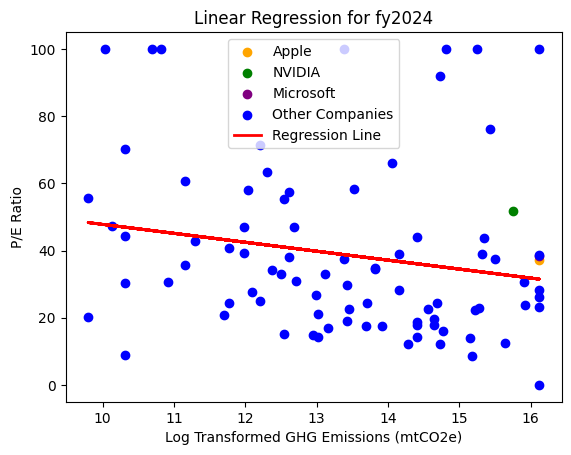

In [ ]:
fy2020.linear_regression_with_companies()
fy2021.linear_regression_with_companies()
fy2022.linear_regression_with_companies()
fy2023.linear_regression_with_companies()
fy2024.linear_regression_with_companies()